# Task 1: Multi-Class Benchmark Classification Pipeline (Iris)End-to-end supervised classification workflow with Scikit-Learn: data loading, exploratory analysis, feature scaling, model training, and benchmarking.### Workflow1. Load dataset with Pandas2. Exploratory analysis (descriptive statistics, duplicates, class balance)3. Train/test split (80/20, stratified)4. Feature scaling with StandardScaler5. Train Logistic Regression and Decision Tree6. Benchmark metrics (accuracy, precision, recall, F1)7. Confusion matrix heatmap + decision boundary visualization### Expected Deliverable- Classification report metrics for both models- Plotted confusion matrix heatmap- Decision boundary visualization


## 1. Load & Explore the Dataset
Import libraries, load the Iris CSV, and inspect the data.

In [1]:
from IPython.display import display

# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="viridis")

# Paths are relative to the notebooks/ directory.
# Run the notebook from notebooks/ (e.g. `jupyter notebook` there).
DATA_PATH = Path("../data/raw/iris.csv")
FIGURE_DIR = Path("../reports/figures")
MODEL_DIR = Path("../models")

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load dataset
df = pd.read_csv(DATA_PATH)

# Display dataset
display(df.head())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



### Dataset dimensions & structure

In [2]:
# Dataset dimensions
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSpecies distribution:")
print(df["species"].value_counts())

Dataset shape: (150, 5)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Descriptive statistics:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 1

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64



### Pairwise relationships

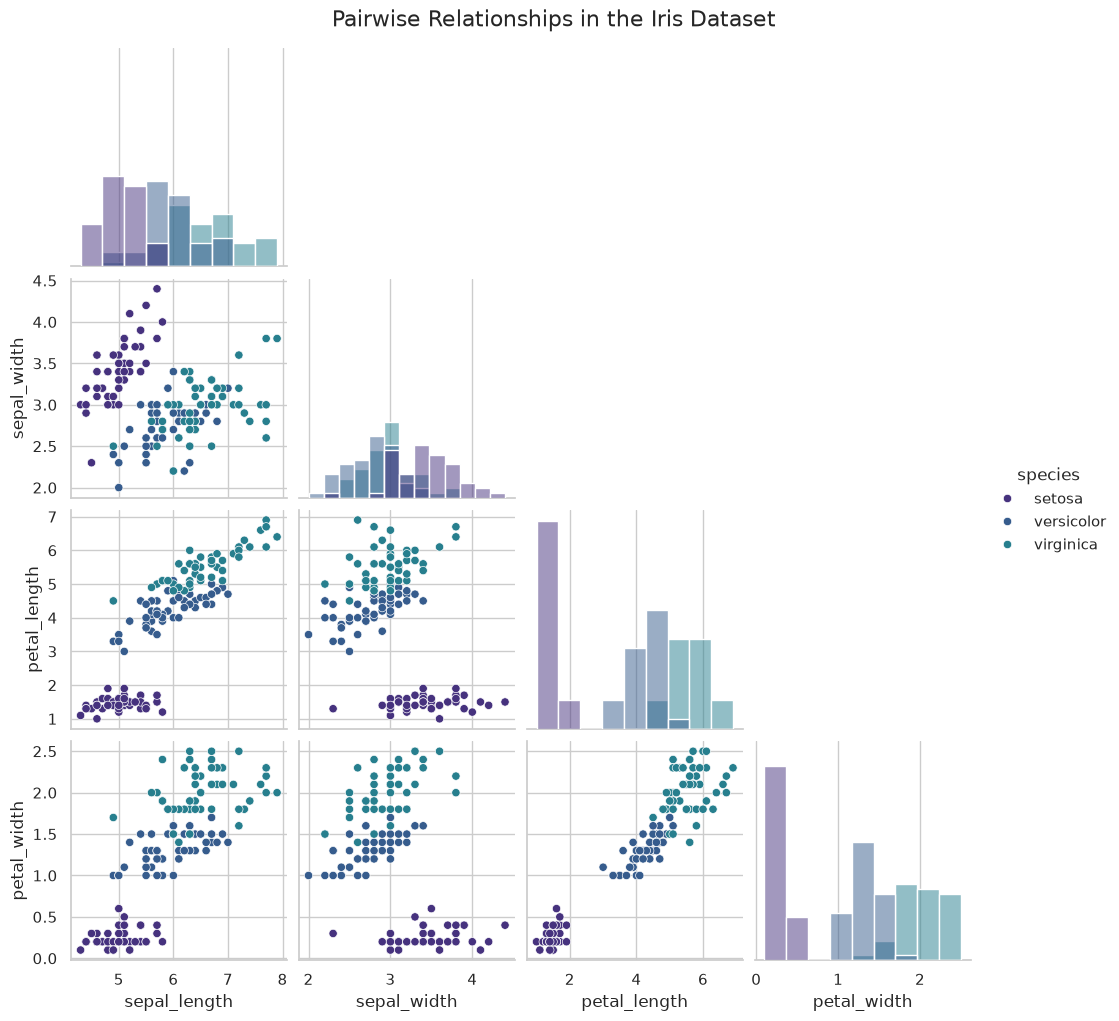

In [3]:
# Visualize relationships between numerical features
sns.pairplot(
    df, hue="species", diag_kind="hist",
    corner=True, height=2.5
)
plt.suptitle("Pairwise Relationships in the Iris Dataset", y=1.02, fontsize=16)
plt.savefig(FIGURE_DIR / "pairplot.png", dpi=150, bbox_inches="tight")
plt.show()


## 2. Clean & Split the Data
Remove duplicates, then split into stratified 80/20 train/test sets.

In [4]:
# Preserve the original dataset
df_original = df.copy()

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

print("Original dataset shape:", df_original.shape)
print("Cleaned dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

print("\nUpdated species distribution:")
print(df["species"].value_counts())

Original dataset shape: (150, 5)
Cleaned dataset shape: (149, 5)
Remaining duplicates: 0

Updated species distribution:
species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64



### Train / Test Split

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop("species", axis=1)
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20, random_state=42, stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (119, 4)
Testing features: (30, 4)

Training target distribution:
species
setosa        40
versicolor    40
virginica     39
Name: count, dtype: int64

Testing target distribution:
species
versicolor    10
virginica     10
setosa        10
Name: count, dtype: int64



## 3. Feature Scaling (StandardScaler)
Scale features so all models train on comparable ranges.

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nTraining feature means:")
print(X_train_scaled.mean(axis=0))

print("\nTraining feature standard deviations:")
print(X_train_scaled.std(axis=0))

Training data shape: (119, 4)
Testing data shape: (30, 4)

Training feature means:
[-5.87765131e-16  4.87005394e-16  2.78022236e-16  3.73184210e-17]

Training feature standard deviations:
[1. 1. 1. 1.]



## 4. Train Models & Benchmark
Train Logistic Regression (scaled) and Decision Tree (unscaled), then benchmark with accuracy, precision, recall, and F1.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Wrap the scaled arrays in DataFrames so the fitted model remembers the
# feature names (sklearn stores them as `feature_names_in_`). The saved
# model is then self-describing, and mismatched inputs fail loudly.
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_scaled_df, y_train)
logistic_predictions = logistic_model.predict(X_test_scaled_df)

logistic_accuracy = accuracy_score(y_test, logistic_predictions)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print(f"Accuracy: {logistic_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, logistic_predictions, zero_division=0))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)

tree_accuracy = accuracy_score(y_test, tree_predictions)

print("DECISION TREE RESULTS")
print("---------------------")
print(f"Accuracy: {tree_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, tree_predictions, zero_division=0))

DECISION TREE RESULTS
---------------------
Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30




### Model Performance Comparison

In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = {
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, tree_predictions)
    ],
    "Precision": [
        precision_score(y_test, logistic_predictions, average="macro"),
        precision_score(y_test, tree_predictions, average="macro")
    ],
    "Recall": [
        recall_score(y_test, logistic_predictions, average="macro"),
        recall_score(y_test, tree_predictions, average="macro")
    ],
    "F1-Score": [
        f1_score(y_test, logistic_predictions, average="macro"),
        f1_score(y_test, tree_predictions, average="macro")
    ]
}

comparison_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)
display(comparison_df.round(4))

top_accuracy = comparison_df["Accuracy"].max()
tied = comparison_df[comparison_df["Accuracy"] == top_accuracy]

print(f"\nTop accuracy: {top_accuracy:.2%}")
if len(tied) > 1:
    print("Tie between: " + ", ".join(tied["Model"]))
    print("Neither model is the better one on this split.")
else:
    print(f"Best model: {tied.iloc[0]['Model']}")

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333



Top accuracy: 93.33%
Tie between: Logistic Regression, Decision Tree
Neither model is the better one on this split.


## 7. Save & Reload the Artifacts
Persist the fitted scaler and models so the benchmark can be reproduced
without retraining, then load them back and confirm they still score
the same accuracy.

In [10]:
import joblib

joblib.dump(scaler, MODEL_DIR / "scaler.pkl")
joblib.dump(logistic_model, MODEL_DIR / "logistic_regression.pkl")
joblib.dump(tree_model, MODEL_DIR / "decision_tree.pkl")

print("Saved artifacts:")
for path in sorted(MODEL_DIR.glob("*.pkl")):
    print(f"  {path}  ({path.stat().st_size:,} bytes)")

print("\nLogistic Regression expects StandardScaler-transformed features.")
print("Fitted feature names:", list(logistic_model.feature_names_in_))

Saved artifacts:
  ../models/decision_tree.pkl  (3,105 bytes)
  ../models/logistic_regression.pkl  (1,407 bytes)
  ../models/scaler.pkl  (983 bytes)

Logistic Regression expects StandardScaler-transformed features.
Fitted feature names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']


In [11]:
# Reload the saved artifacts and confirm they reproduce the benchmark.
loaded_scaler = joblib.load(MODEL_DIR / "scaler.pkl")
loaded_lr = joblib.load(MODEL_DIR / "logistic_regression.pkl")
loaded_dt = joblib.load(MODEL_DIR / "decision_tree.pkl")

X_test_reloaded = pd.DataFrame(
    loaded_scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)
lr_reloaded_acc = accuracy_score(y_test, loaded_lr.predict(X_test_reloaded))
dt_reloaded_acc = accuracy_score(y_test, loaded_dt.predict(X_test))

print(f"Reloaded Logistic Regression accuracy: {lr_reloaded_acc:.4f}")
print(f"Reloaded Decision Tree accuracy:       {dt_reloaded_acc:.4f}")

assert np.isclose(lr_reloaded_acc, logistic_accuracy), "LR artifact does not reproduce the benchmark"
assert np.isclose(dt_reloaded_acc, tree_accuracy), "DT artifact does not reproduce the benchmark"
print("\nSaved artifacts verified: both reload and reproduce the benchmark.")

Reloaded Logistic Regression accuracy: 0.9333
Reloaded Decision Tree accuracy:       0.9333

Saved artifacts verified: both reload and reproduce the benchmark.



## 5. Confusion Matrix Heatmap
Visualize per-class prediction performance for both models.

In [12]:
from sklearn.metrics import confusion_matrix

logistic_cm = confusion_matrix(y_test, logistic_predictions, labels=logistic_model.classes_)
tree_cm = confusion_matrix(y_test, tree_predictions, labels=tree_model.classes_)

print("Logistic Regression Confusion Matrix:")
print(logistic_cm)

print("\nDecision Tree Confusion Matrix:")
print(tree_cm)

Logistic Regression Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Decision Tree Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


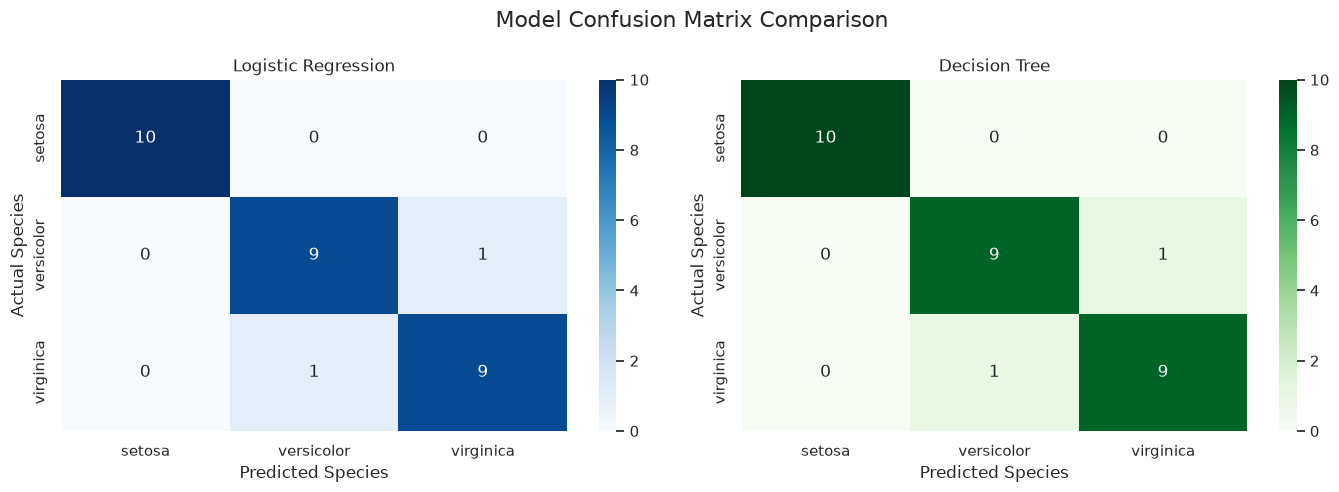

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(logistic_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=logistic_model.classes_,
            yticklabels=logistic_model.classes_, ax=axes[0])
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted Species")
axes[0].set_ylabel("Actual Species")

sns.heatmap(tree_cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=tree_model.classes_,
            yticklabels=tree_model.classes_, ax=axes[1])
axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted Species")
axes[1].set_ylabel("Actual Species")

plt.suptitle("Model Confusion Matrix Comparison", fontsize=16)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Decision Boundary Visualization
Petal length and petal width are selected for visualization because they provide good separation between the Iris species.

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
import numpy as np
import matplotlib.pyplot as plt

features = ["petal_length", "petal_width"]
X_pair_train = X_train[features]

class_names = sorted(y_train.unique())
class_to_number = {species: idx for idx, species in enumerate(class_names)}
y_train_encoded = y_train.map(class_to_number)

print("Features selected:", features)
print("Species:", class_names)

Features selected: ['petal_length', 'petal_width']
Species: ['setosa', 'versicolor', 'virginica']


In [15]:
pair_scaler = StandardScaler()
X_pair_train_scaled = pair_scaler.fit_transform(X_pair_train)

pair_logistic = LogisticRegression(max_iter=1000, random_state=42)
pair_logistic.fit(X_pair_train_scaled, y_train)

pair_tree = DecisionTreeClassifier(random_state=42)
pair_tree.fit(X_pair_train, y_train)

print("Visualization models trained successfully!")

Visualization models trained successfully!


In [16]:
x_min = X_pair_train["petal_length"].min() - 0.5
x_max = X_pair_train["petal_length"].max() + 0.5
y_min = X_pair_train["petal_width"].min() - 0.5
y_max = X_pair_train["petal_width"].max() + 0.5

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))

grid_points = pd.DataFrame({"petal_length": xx.ravel(),
                            "petal_width": yy.ravel()})

grid_scaled = pair_scaler.transform(grid_points)
logistic_grid_predictions = pair_logistic.predict(grid_scaled)

tree_grid_predictions = pair_tree.predict(grid_points)

logistic_Z = np.array([class_to_number[s] for s in logistic_grid_predictions]).reshape(xx.shape)
tree_Z = np.array([class_to_number[s] for s in tree_grid_predictions]).reshape(xx.shape)

print("Decision boundaries generated successfully!")

Decision boundaries generated successfully!


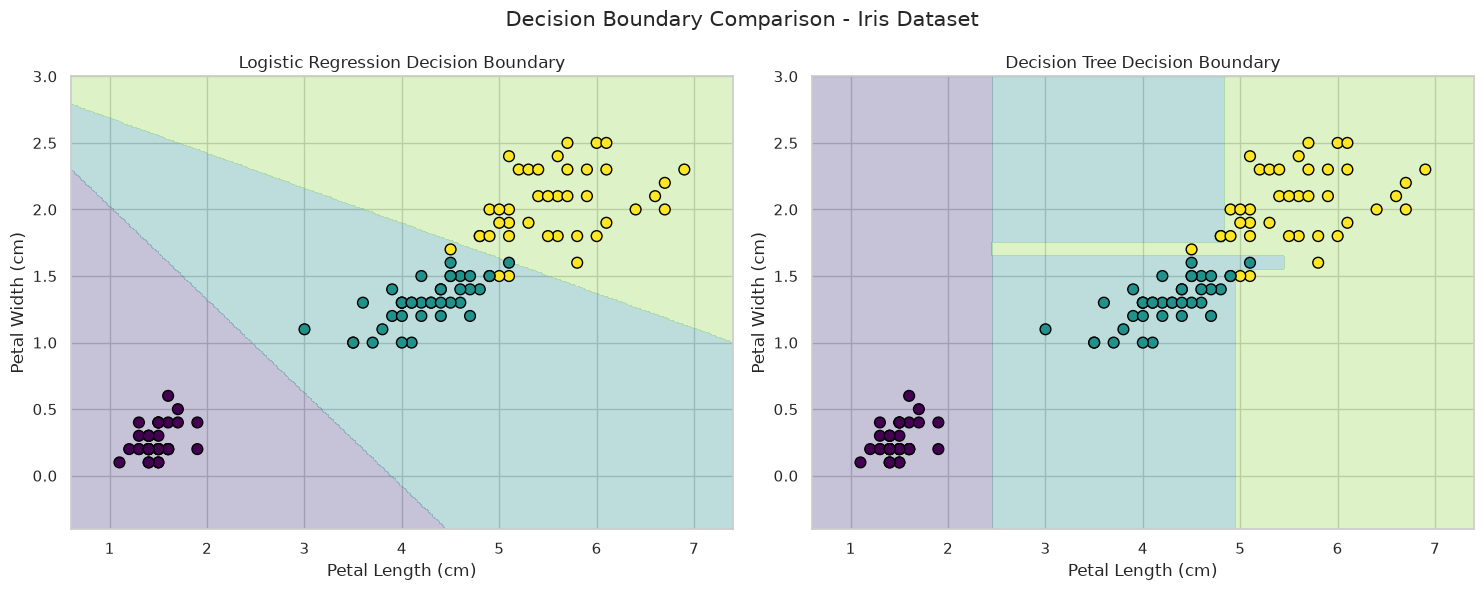

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].contourf(xx, yy, logistic_Z, alpha=0.3, cmap="viridis", levels=np.arange(-0.5, 3, 1))
axes[0].scatter(X_pair_train["petal_length"], X_pair_train["petal_width"],
                c=y_train_encoded, cmap="viridis", edgecolors="black", s=60)
axes[0].set_title("Logistic Regression Decision Boundary")
axes[0].set_xlabel("Petal Length (cm)")
axes[0].set_ylabel("Petal Width (cm)")

axes[1].contourf(xx, yy, tree_Z, alpha=0.3, cmap="viridis", levels=np.arange(-0.5, 3, 1))
axes[1].scatter(X_pair_train["petal_length"], X_pair_train["petal_width"],
                c=y_train_encoded, cmap="viridis", edgecolors="black", s=60)
axes[1].set_title("Decision Tree Decision Boundary")
axes[1].set_xlabel("Petal Length (cm)")
axes[1].set_ylabel("Petal Width (cm)")

plt.suptitle("Decision Boundary Comparison - Iris Dataset", fontsize=15)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "decision_boundary.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary

Both **Logistic Regression** and **Decision Tree** achieved the same benchmark
performance on the Iris dataset (80/20 stratified split, `random_state=42`):

- **Accuracy**: 93.33%
- **Precision (macro)**: 93.33%
- **Recall (macro)**: 93.33%
- **F1-Score (macro)**: 93.33%

The two models are tied on every headline metric, so neither is the better model
on this split. Logistic Regression is listed first only because `idxmax()` returns
the first row when values are equal. Both models classify all 10 setosa test samples
correctly and each misses one versicolor/virginica boundary case.

### Artifacts written by this notebook

- `reports/figures/pairplot.png`
- `reports/figures/confusion_matrix.png`
- `reports/figures/decision_boundary.png`
- `models/scaler.pkl` - fitted `StandardScaler`; required by the Logistic Regression model
- `models/logistic_regression.pkl`
- `models/decision_tree.pkl`

The decision boundary visualization confirms that petal length and petal width are
the most discriminative features for the three Iris species.